# 06 · Evidence verification, statistics and tests

<a id="SETUP"></a>
### `SETUP` · Setup: component environment and immutable evidence

In [2]:
# Code block: 14-SETUP
from pathlib import Path
import sys
WORKSPACE = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'source/bpdr_input').is_dir())
sys.path.insert(0, str(WORKSPACE / 'source'))
from bpdr_input.reporting.notebook_setup import prepare, load_catalogs, show
globals().update(prepare(WORKSPACE))
show(pd.DataFrame([{'check': 'Saved model and evidence identities', 'result': 'PASS',
                    'recorded_run': RUN.name}]))


,check,result,recorded_run
0,Saved model and evidence identities,PASS,b4c64c3b861a48c494c092458716b4fc


<a id="VERIFY-ENVIRONMENT"></a>
### Verification environment


In [3]:
# Code block: VERIFY-ENVIRONMENT
from importlib.metadata import version
packages = ['numpy', 'scipy', 'pandas', 'torch', 'scikit-learn',
            'joblib', 'librosa', 'pesto-pitch', 'praat-parselmouth', 'nbformat']
show(pd.DataFrame([dict(package=p, verification_version=version(p)) for p in packages]))

,package,verification_version
0,numpy,2.5.3
1,scipy,1.18.1
2,pandas,3.0.6
3,torch,2.14.0
4,scikit-learn,1.9.1
5,joblib,1.6.0
6,librosa,1.0.0
7,pesto-pitch,2.0.1
8,praat-parselmouth,0.4.7
9,nbformat,5.11.1


<a id="CONTEXT"></a>
### `CONTEXT` · Load local split catalogs and common helper names

In [4]:
# Code block: 14-CONTEXT
globals().update(load_catalogs(RUN, MANIFEST))
show(pd.DataFrame([
    dict(split=s, recordings=len(SOURCE_RECORDS[s]), singers=len(groups[s]),
         intervention_attempts=len(PAIRS[s])) for s in SPLITS
]))


,split,recordings,singers,intervention_attempts
0,train,16,8,64
1,calibration,4,2,16
2,pilot_evaluation,4,2,16


<a id="VERIFY-METRICS"></a>
### `VERIFY-METRICS` · Independent metric arithmetic and tests of empty/missing masks

In [7]:
# Code block: VERIFY-METRICS
example = fixed_metrics(np.array([-20.0, -21.0, 30.0]), np.array([-30.0, -30.0, -30.0]), np.array([True, True, True]))
assert np.isclose(example['mae_cents'], 79 / 3) and np.isclose(example['within_tolerance_percent'], 200 / 3)
print('Checked toy arithmetic:', example)
for prediction, mask in [(np.array([0.0]), np.array([False])), (np.array([np.nan]), np.array([True]))]:
    try:
        fixed_metrics(prediction, np.array([0.0]), mask)
    except ValueError as exc:
        print('Expected blocked metric:', exc)
    else:
        raise AssertionError('Invalid metric was accepted')

Checked toy arithmetic: {'frames': 3, 'mae_cents': 26.333333333333332, 'within_tolerance_percent': 66.66666666666666}
Expected blocked metric: A nonempty fixed mask and positive finite tolerance are required
Expected blocked metric: Missing scored pitch must be reported, not dropped from the denominator


 The toy arithmetic is checked independently. Empty masks and missing predictions are rejected, rather than reported as zero error or silently dropped.

<a id="PILOT-DIRECTION"></a>
### `PILOT-DIRECTION` · Separate positive and negative delivered outcomes

In [9]:
# Code block: PILOT-DIRECTION
SCORED = pd.DataFrame(AUDIT['scored'])
show(SCORED)

,singer,recording,shift,before,after,improved,outcome,scored_frames
0,male6,C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\BPDR_Workspace\results\model_recovery\b4c64c3b861a48c494c092458716b4fc\pilot_evaluation\prepared\02\original_working.wav,-30.0000,30.8083,30.8083,False,VERIFIED_FIXTURE_CANDIDATE,33
1,male6,C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\BPDR_Workspace\results\model_recovery\b4c64c3b861a48c494c092458716b4fc\pilot_evaluation\prepared\02\original_working.wav,20.0000,19.5138,19.5138,False,WITHHELD,34
2,male6,C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\BPDR_Workspace\results\model_recovery\b4c64c3b861a48c494c092458716b4fc\pilot_evaluation\prepared\02\original_working.wav,30.0000,29.2022,5.4249,True,VERIFIED_FIXTURE_CANDIDATE,36
3,male6,C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\BPDR_Workspace\results\model_recovery\b4c64c3b861a48c494c092458716b4fc\pilot_evaluation\prepared\03\original_working.wav,30.0000,30.2433,2.9051,True,VERIFIED_FIXTURE_CANDIDATE,34


<a id="PILOT-DIRECTION-2"></a>
#### Inspect the result

In [10]:
# Code block: PILOT-DIRECTION-2
show(SCORED.groupby('shift').agg(cases=('shift', 'size'), input_MAE=('before', 'mean'), output_MAE=('after', 'mean'), improvements=('improved', 'sum')))

,cases,input_MAE,output_MAE,improvements
shift,,,,
-30.000000,1,30.8083,30.8083,0
20.000000,1,19.5138,19.5138,0
30.000000,2,29.7227,4.1650,2


<a id="PILOT-DIRECTION-3"></a>
#### Prepare or verify the next result

In [11]:
# Code block: PILOT-DIRECTION-3
print('All scoreable pilot cases:', AUDIT['pilot_summary'])

All scoreable pilot cases: {'cases': 4, 'before_mae_cents': 27.44190742699078, 'after_mae_cents': 14.663040953839834, 'mean_paired_improvement_cents': 12.778866473150943, 'relative_reduction_percent': 46.56697610087467}


<a id="PILOT-DIRECTION-4"></a>
#### Visualize the result

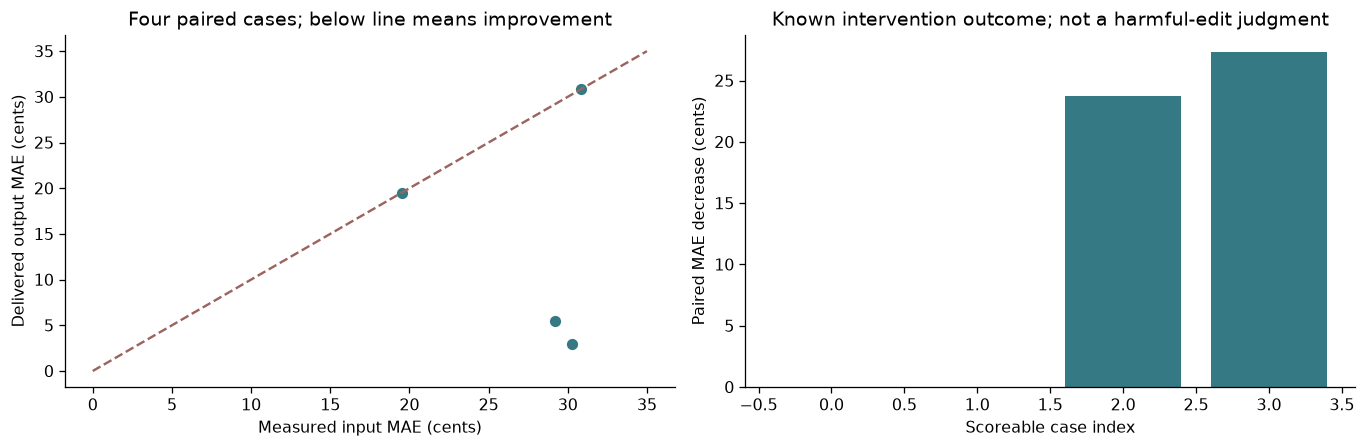

In [12]:
# Code block: PILOT-DIRECTION-4
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(SCORED.before, SCORED.after, color=COLORS['output'])
axes[0].plot([0, 35], [0, 35], linestyle='--', color=COLORS['input'])
axes[0].set(xlabel='Measured input MAE (cents)', ylabel='Delivered output MAE (cents)', title='Four paired cases; below line means improvement')
axes[1].bar(np.arange(len(SCORED)), SCORED.before - SCORED.after, color=COLORS['output'])
axes[1].set(xlabel='Scoreable case index', ylabel='Paired MAE decrease (cents)', title='Known intervention outcome; not a harmful-edit judgment')
plt.tight_layout()
plt.show()

**Read the output.** Below the diagonal means lower delivered error. Read positive and negative shifts separately; favorable aggregate results do not establish symmetric recovery.

<a id="PILOT-STATISTICS"></a>
### `PILOT-STATISTICS` · Independent units, failures, latency and uncertainty

In [13]:
# Code block: PILOT-STATISTICS
print('Scoreable singers:', SCORED.singer.nunique(), '; scoreable original recordings:', SCORED.recording.nunique())
show(SCORED.groupby(['singer', 'recording']).agg(cases=('shift', 'size'), before_MAE=('before', 'mean'), after_MAE=('after', 'mean')))

Scoreable singers: 1 ; scoreable original recordings: 2


cases  before_MAE  after_MAE
singer recording                                                                                                                                                                                                                   
male6  C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\BPDR_Workspace\results\model_recovery\b4c64c3b861a48c494c092458716b4fc\pilot_evaluation\prepared\02\original_working.wav      3   26.508119  18.582352
       C:\Users\lnipu\Projects\Music Rp\RP\J26-DS-339\experiments\bpdr_input\BPDR_Workspace\results\model_recovery\b4c64c3b861a48c494c092458716b4fc\pilot_evaluation\prepared\03\original_working.wav      1   30.243271   2.905106

<a id="PILOT-STATISTICS-2"></a>
#### Inspect the result

In [14]:
# Code block: PILOT-STATISTICS-2
print('Population CI: NOT APPLICABLE with one scoreable pilot singer; no correlated-frame bootstrap is presented.')
verification = read_json(RUN / 'rendered_verification.json')
outcomes = Counter((r['outcome'] for r in verification['shifts'] if 'excluded' not in r))
show(pd.DataFrame([dict(outcome=k, cases=v) for k, v in outcomes.items()]))

Population CI: NOT APPLICABLE with one scoreable pilot singer; no correlated-frame bootstrap is presented.


,outcome,cases
0,VERIFIED_FIXTURE_CANDIDATE,3
1,WITHHELD,1


<a id="PILOT-STATISTICS-3"></a>
#### Prepare or verify the next result

In [15]:
# Code block: PILOT-STATISTICS-3
print('Recorded all-case replay seconds:', verification['elapsed_seconds'], '; this is a whole verification pass, not per-request latency.')
print('Memory peak / p50 / p95 latency / independently judged harmful-edit rate: NOT VERIFIED in this study.')

Recorded all-case replay seconds: 22.468 ; this is a whole verification pass, not per-request latency.
Memory peak / p50 / p95 latency / independently judged harmful-edit rate: NOT VERIFIED in this study.


**Read the output.** The scoreable cases contain one singer and two original recordings. Repeated frames/variants do not create independent people. Whole-pass replay time is not per-request latency; population confidence intervals and latency percentiles remain unavailable.

<a id="VERIFY-TESTS"></a>
### `VERIFY-TESTS` · Run relevant existing tests and new metric/sign guards

In [16]:
# Code block: VERIFY-TESTS
import unittest, io, time
test_root = WORKSPACE / 'tests'
suite = unittest.TestSuite()
patterns = ['test_notebook_training.py', 'test_research_support.py', 'test_phase3.py', 'test_recovery_model.py', 'test_recovery_selection.py', 'test_learned_delivery.py', 'test_repair_controller.py', 'test_framewise_renderer.py', 'test_framewise_audit.py', 'test_demo_review.py']
for pattern in patterns:
    suite.addTests(unittest.defaultTestLoader.discover(str(test_root), pattern=pattern))
stream = io.StringIO()
started = time.perf_counter()
result = unittest.TextTestRunner(stream=stream, verbosity=1).run(suite)
print(stream.getvalue())
print('Test seconds:', round(time.perf_counter() - started, 3))
assert result.wasSuccessful(), 'Test failures remain visible above; do not present this run as passing.'
print('Executed tests:', result.testsRun, '; failures:', len(result.failures), '; errors:', len(result.errors))

.................................................................
----------------------------------------------------------------------
Ran 65 tests in 51.490s

OK

Test seconds: 51.491
Executed tests: 65 ; failures: 0 ; errors: 0


**Read the output.** Passing tests support software behavior, metric guards and contract mechanics. They do not establish natural singing correctness or population-level research validity.